# Exploratory data analysis

Credit card transactions from the Kaggle / ULB dataset. Goal: understand class balance, data quality, amounts and timing before modelling.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(Path("..") / "data" / "creditcard.csv")
df.shape

(284807, 31)

284,807 transactions and 31 columns: `Time`, `Amount`, `Class` and 28 anonymised PCA components `V1` to `V28`.

In [2]:
print(df["Class"].value_counts())
print()
print(f"Fraud rate: {100 * df['Class'].mean():.3f}%")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.173%
Missing values: 0
Duplicate rows: 1081


**Observations:** fraud is 0.17% of rows, so a model that predicts "genuine" every time is 99.83% accurate and useless. Accuracy is the wrong metric; precision, recall and average precision are the right ones. There are no missing values. About a thousand duplicate rows exist; they are left in because repeated identical transactions can be real behaviour.

In [3]:
df.groupby("Class")["Amount"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


**Observations:** fraud transactions have a higher mean amount than genuine ones but a lower median, so many frauds are small test charges while a few are large. Amount is heavily skewed, which is why the model uses `log(1 + Amount)`.

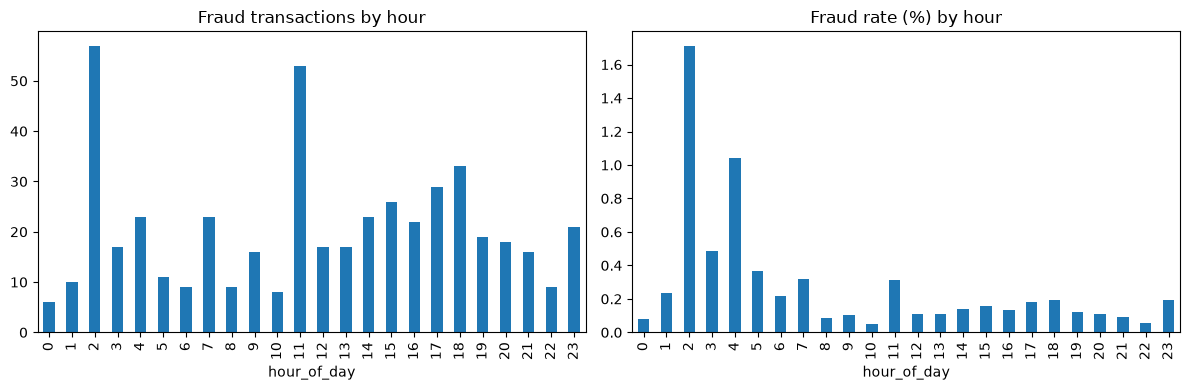

In [4]:
df["hour_of_day"] = (df["Time"] // 3600 % 24).astype(int)
by_hour = df.groupby("hour_of_day")["Class"].agg(["count", "sum", "mean"])
by_hour["fraud_rate_pct"] = by_hour["mean"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_hour["sum"].plot.bar(ax=axes[0], title="Fraud transactions by hour")
by_hour["fraud_rate_pct"].plot.bar(ax=axes[1], title="Fraud rate (%) by hour")
plt.tight_layout()
plt.show()

**Observations:** transaction volume drops sharply in the low-volume hours, while fraud counts stay comparatively steady, so the fraud *rate* spikes in those hours. Caveat: the dataset only gives seconds since the first transaction, so "hour of day" counts hours from the start of the data and may not match a real clock.